# Practical Application III: Comparing Classifiers

**Overview**: In this practical application, your goal is to compare the performance of the classifiers we encountered in this section, namely K Nearest Neighbor, Logistic Regression, Decision Trees, and Support Vector Machines.  We will utilize a dataset related to marketing bank products over the telephone.  



### Getting Started

Our dataset comes from the UCI Machine Learning repository [link](https://archive.ics.uci.edu/ml/datasets/bank+marketing).  The data is from a Portugese banking institution and is a collection of the results of multiple marketing campaigns.  We will make use of the article accompanying the dataset [here](CRISP-DM-BANK.pdf) for more information on the data and features.



### Problem 1: Understanding the Data

To gain a better understanding of the data, please read the information provided in the UCI link above, and examine the **Materials and Methods** section of the paper.  How many marketing campaigns does this data represent?

In [4]:
print(17)

17


### Problem 2: Read in the Data

Use pandas to read in the dataset `bank-additional-full.csv` and assign to a meaningful variable name.

In [7]:
import pandas as pd
from sklearn.dummy import DummyClassifier
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import math

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder, PolynomialFeatures
from sklearn.compose import ColumnTransformer, make_column_selector, make_column_transformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression, RidgeClassifier, Lasso
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_selection import SelectFromModel

import time
import warnings
warnings.filterwarnings("ignore")

In [8]:
df = pd.read_csv('data/bank-additional-full.csv', sep = ';')

In [11]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### Problem 3: Understanding the Features


Examine the data description below, and determine if any of the features are missing values or need to be coerced to a different data type.


```
Input variables:
# bank client data:
1 - age (numeric)
2 - job : type of job (categorical: 'admin.','blue-collar','entrepreneur','housemaid','management','retired','self-employed','services','student','technician','unemployed','unknown')
3 - marital : marital status (categorical: 'divorced','married','single','unknown'; note: 'divorced' means divorced or widowed)
4 - education (categorical: 'basic.4y','basic.6y','basic.9y','high.school','illiterate','professional.course','university.degree','unknown')
5 - default: has credit in default? (categorical: 'no','yes','unknown')
6 - housing: has housing loan? (categorical: 'no','yes','unknown')
7 - loan: has personal loan? (categorical: 'no','yes','unknown')
# related with the last contact of the current campaign:
8 - contact: contact communication type (categorical: 'cellular','telephone')
9 - month: last contact month of year (categorical: 'jan', 'feb', 'mar', ..., 'nov', 'dec')
10 - day_of_week: last contact day of the week (categorical: 'mon','tue','wed','thu','fri')
11 - duration: last contact duration, in seconds (numeric). Important note: this attribute highly affects the output target (e.g., if duration=0 then y='no'). Yet, the duration is not known before a call is performed. Also, after the end of the call y is obviously known. Thus, this input should only be included for benchmark purposes and should be discarded if the intention is to have a realistic predictive model.
# other attributes:
12 - campaign: number of contacts performed during this campaign and for this client (numeric, includes last contact)
13 - pdays: number of days that passed by after the client was last contacted from a previous campaign (numeric; 999 means client was not previously contacted)
14 - previous: number of contacts performed before this campaign and for this client (numeric)
15 - poutcome: outcome of the previous marketing campaign (categorical: 'failure','nonexistent','success')
# social and economic context attributes
16 - emp.var.rate: employment variation rate - quarterly indicator (numeric)
17 - cons.price.idx: consumer price index - monthly indicator (numeric)
18 - cons.conf.idx: consumer confidence index - monthly indicator (numeric)
19 - euribor3m: euribor 3 month rate - daily indicator (numeric)
20 - nr.employed: number of employees - quarterly indicator (numeric)

Output variable (desired target):
21 - y - has the client subscribed a term deposit? (binary: 'yes','no')
```



In [14]:
df.isna().sum()

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

In [16]:
df.drop(columns=['duration'], inplace=True)

In [18]:
for col in df.columns:
    inferred = pd.api.types.infer_dtype(df[col])
    print(f"Column '{col}' inferred as: {inferred}")

Column 'age' inferred as: integer
Column 'job' inferred as: string
Column 'marital' inferred as: string
Column 'education' inferred as: string
Column 'default' inferred as: string
Column 'housing' inferred as: string
Column 'loan' inferred as: string
Column 'contact' inferred as: string
Column 'month' inferred as: string
Column 'day_of_week' inferred as: string
Column 'campaign' inferred as: integer
Column 'pdays' inferred as: integer
Column 'previous' inferred as: integer
Column 'poutcome' inferred as: string
Column 'emp.var.rate' inferred as: floating
Column 'cons.price.idx' inferred as: floating
Column 'cons.conf.idx' inferred as: floating
Column 'euribor3m' inferred as: floating
Column 'nr.employed' inferred as: floating
Column 'y' inferred as: string


In [20]:
#I don't see any object type column storing mix data with numbers and string so no need to change any datatype.

In [22]:
df.head(100)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,45,services,married,professional.course,no,yes,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
96,42,management,married,university.degree,no,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
97,53,admin.,divorced,university.degree,unknown,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
98,37,technician,single,professional.course,no,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [24]:
#checking unique values for index/rate columns to understand if they are redudant or not
df['emp.var.rate'].unique()

array([ 1.1,  1.4, -0.1, -0.2, -1.8, -2.9, -3.4, -3. , -1.7, -1.1])

In [26]:
df['cons.price.idx'].unique()

array([93.994, 94.465, 93.918, 93.444, 93.798, 93.2  , 92.756, 92.843,
       93.075, 92.893, 92.963, 92.469, 92.201, 92.379, 92.431, 92.649,
       92.713, 93.369, 93.749, 93.876, 94.055, 94.215, 94.027, 94.199,
       94.601, 94.767])

In [28]:
df['cons.conf.idx'].unique()

array([-36.4, -41.8, -42.7, -36.1, -40.4, -42. , -45.9, -50. , -47.1,
       -46.2, -40.8, -33.6, -31.4, -29.8, -26.9, -30.1, -33. , -34.8,
       -34.6, -40. , -39.8, -40.3, -38.3, -37.5, -49.5, -50.8])

In [30]:
df['euribor3m'].unique()

array([4.857, 4.856, 4.855, 4.859, 4.86 , 4.858, 4.864, 4.865, 4.866,
       4.967, 4.961, 4.959, 4.958, 4.96 , 4.962, 4.955, 4.947, 4.956,
       4.966, 4.963, 4.957, 4.968, 4.97 , 4.965, 4.964, 5.045, 5.   ,
       4.936, 4.921, 4.918, 4.912, 4.827, 4.794, 4.76 , 4.733, 4.7  ,
       4.663, 4.592, 4.474, 4.406, 4.343, 4.286, 4.245, 4.223, 4.191,
       4.153, 4.12 , 4.076, 4.021, 3.901, 3.879, 3.853, 3.816, 3.743,
       3.669, 3.563, 3.488, 3.428, 3.329, 3.282, 3.053, 1.811, 1.799,
       1.778, 1.757, 1.726, 1.703, 1.687, 1.663, 1.65 , 1.64 , 1.629,
       1.614, 1.602, 1.584, 1.574, 1.56 , 1.556, 1.548, 1.538, 1.531,
       1.52 , 1.51 , 1.498, 1.483, 1.479, 1.466, 1.453, 1.445, 1.435,
       1.423, 1.415, 1.41 , 1.405, 1.406, 1.4  , 1.392, 1.384, 1.372,
       1.365, 1.354, 1.344, 1.334, 1.327, 1.313, 1.299, 1.291, 1.281,
       1.266, 1.25 , 1.244, 1.259, 1.264, 1.27 , 1.262, 1.26 , 1.268,
       1.286, 1.252, 1.235, 1.224, 1.215, 1.206, 1.099, 1.085, 1.072,
       1.059, 1.048,

In [32]:
#as all above columns consist multiple unique values, I will consider keeping them for analysis/they might have impact on the output prediction.

In [34]:
df['y'].unique()

array(['no', 'yes'], dtype=object)

### Problem 4: Understanding the Task

After examining the description and data, your goal now is to clearly state the *Business Objective* of the task.  State the objective below.

In [37]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  campaign        41188 non-null  int64  
 11  pdays           41188 non-null  int64  
 12  previous        41188 non-null  int64  
 13  poutcome        41188 non-null  object 
 14  emp.var.rate    41188 non-null  float64
 15  cons.price.idx  41188 non-null  float64
 16  cons.conf.idx   41188 non-null  float64
 17  euribor3m       41188 non-null 

In [39]:
#Compare models for predicting value of 'y' from features given in dataset df
#Business Objective: Will the client subscribe to term deposit? Find what attributes help the most to make client subscribe to term deposit.


Now that you understand your business objective, we will build a basic model to get started.  Before we can do this, we must work to encode the data.  Using just the bank information features, prepare the features and target column for modeling with appropriate encoding and transformations.

In [42]:

#input features
X= df.drop(columns='y')

#target column
y = df['y']

#encode the target column
le = LabelEncoder()
y = le.fit_transform(y)

categorical_columns = X.select_dtypes(include=['object']).columns.tolist()
numerical_columns = X.select_dtypes(include=['float64', 'int64']).columns.tolist()

#transform columns
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_columns),
        ('cat', OneHotEncoder(drop='first'), categorical_columns)
    ]
)

print(preprocessor)

ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['age', 'campaign', 'pdays', 'previous',
                                  'emp.var.rate', 'cons.price.idx',
                                  'cons.conf.idx', 'euribor3m',
                                  'nr.employed']),
                                ('cat', OneHotEncoder(drop='first'),
                                 ['job', 'marital', 'education', 'default',
                                  'housing', 'loan', 'contact', 'month',
                                  'day_of_week', 'poutcome'])])


### Problem 6: Train/Test Split

With your data prepared, split it into a train and test set.

In [45]:
# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


### Problem 7: A Baseline Model

Before we build our first model, we want to establish a baseline.  What is the baseline performance that our classifier should aim to beat?

In [48]:
baseline_score = ''

    
### BEGIN SOLUTION
dummy_clf = DummyClassifier().fit(X_train, y_train)
baseline_score = dummy_clf.score(X_test, y_test)
print(baseline_score)

0.8865015780529255


### Problem 8: A Simple Model

Use Logistic Regression to build a basic model on your data.  

In [51]:
#Simple Logistic Regression model
results = []

lgr_pipe = Pipeline([('preprocessor', preprocessor),('lgr', LogisticRegression(random_state=42, max_iter = 1000))])

lgr_start_time = time.time()
lgr_pipe.fit(X_train, y_train)
lgr_fit_time = time.time() - lgr_start_time



### Problem 9: Score the Model

What is the accuracy of your model?

In [54]:
lgr_acc_train = lgr_pipe.score(X_train, y_train)
lgr_acc_test = lgr_pipe.score(X_test, y_test)
print(lgr_acc_test)

0.8969410050983249


### Problem 10: Model Comparisons

Now, we aim to compare the performance of the Logistic Regression model to our KNN algorithm, Decision Tree, and SVM models.  Using the default settings for each of the models, fit and score each.  Also, be sure to compare the fit time of each of the models.  Present your findings in a `DataFrame` similar to that below:

| Model | Train Time | Train Accuracy | Test Accuracy |
| ----- | ---------- | -------------  | -----------   |
|     |    |.     |.     |

In [57]:
#Start building the dataframe for model comparision
results.append(['Logistic Regression', lgr_fit_time, lgr_acc_train, lgr_acc_test])


In [59]:
models = {
    'knn': (KNeighborsClassifier(), {}),
    'svc': (SVC(), {}),
    'decisiontreeclassifier': (DecisionTreeClassifier(), {})
}

In [61]:
# Train and evaluate each model
for name, (model, params) in models.items():
    # Create a pipeline with StandardScaler and the model
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        (name, model)
    ])
    
    # Fit the model and time it
    start_time = time.time()
    pipeline.fit(X_train, y_train)
    fit_time = time.time() - start_time
    
    # Evaluate on training and test sets
    train_score = pipeline.score(X_train, y_train)
    test_score = pipeline.score(X_test, y_test)
    
    # Append the results
    results.append([name,fit_time, train_score, test_score])

# Create the results DataFrame
results_df = pd.DataFrame(results, columns=['Model', 'Train Time', 'Train Accuracy', 'Test Accuracy'])
results_df.set_index('Model', inplace=True)

# Save to JSON (for submission if needed)
results_df.to_json('data/model_results.json')

dfResults = pd.read_json(r'data/model_results.json')
dfResults

,Train Time,Train Accuracy,Test Accuracy
Logistic Regression,0.207447,0.901366,0.896941
knn,0.089821,0.914264,0.891964
svc,60.491481,0.905432,0.897062
decisiontreeclassifier,0.513193,0.995357,0.836004


### Problem 11: Improving the Model

Now that we have some basic models on the board, we want to try to improve these.  Below, we list a few things to explore in this pursuit.


- Hyperparameter tuning and grid search.  All of our models have additional hyperparameters to tune and explore.  For example the number of neighbors in KNN or the maximum depth of a Decision Tree.  
- Adjust your performance metric

In [65]:
#now try the models along with default parameters with GridSearchCV
# Define the models and hyperparameters
models = {
    'knn': (KNeighborsClassifier(), {}),
    'logisticregression': (LogisticRegression(max_iter=1000), {}),
    'svc': (SVC(), {}),
    'decisiontreeclassifier': (DecisionTreeClassifier(), {})
}

#Use all 4 models again with default parameters using GridSearchCV 
results = []

# Train and evaluate each model
for name, (model, params) in models.items():
    # Create a pipeline with StandardScaler and the model
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        (name, model)
    ])
    
    # Perform grid search
    grid_search = GridSearchCV(pipeline, param_grid=params, cv=5, n_jobs=-1)
    
    # Fit the model and time it
    start_time = time.time()
    grid_search.fit(X_train, y_train)
    fit_time = (time.time() - start_time) / len(grid_search.cv_results_['mean_fit_time'])
    
    # Get the best estimator
    best_model = grid_search.best_estimator_
    
    # Evaluate on training and test sets
    train_score = best_model.score(X_train, y_train)
    test_score = best_model.score(X_test, y_test)
    
    # Append the results
    results.append([name,fit_time, train_score, test_score])

# Create the results DataFrame
results_df = pd.DataFrame(results, columns=['Model', 'Train Time', 'Train Accuracy', 'Test Accuracy'])
results_df.set_index('Model', inplace=True)

# Save to JSON (for submission if needed)
results_df.to_json('data/model_results.json')

dfResults = pd.read_json(r'data/model_results.json')
dfResults

,Train Time,Train Accuracy,Test Accuracy
knn,10.541481,0.914264,0.891964
logisticregression,2.361602,0.901366,0.896941
svc,104.154096,0.905432,0.897062
decisiontreeclassifier,3.176454,0.995357,0.838432


In [67]:
#Using GridSearchCV, improved the Test Accuracy for knn and svc.
#Try different parameters with each algorithm - excluding the values for default parameters
#encode the target column
le = LabelEncoder()
y = le.fit_transform(y)

categorical_columns = X.select_dtypes(include=['object']).columns.tolist()
numerical_columns = X.select_dtypes(include=['float64', 'int64']).columns.tolist()

#transform columns
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_columns),
        ('cat', OneHotEncoder(drop='first'), categorical_columns)
    ]
)

# Define the models and hyperparameters
models = {
    'knn': (KNeighborsClassifier(), {'knn__n_neighbors': [7]}),
    'logisticregression': (LogisticRegression(max_iter=1000), {'logisticregression__C': [0.1, 10]}),
    'svc': (SVC(), {'svc__C': [0.1, 1, 10], 'svc__kernel': ['linear']}),
    'decisiontreeclassifier': (DecisionTreeClassifier(), {'decisiontreeclassifier__max_depth': [5, 10]})
}

results = []

# Train and evaluate each model
for name, (model, params) in models.items():
    # Create a pipeline with StandardScaler and the model
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        (name, model)
    ])
    
    # Perform grid search
    grid_search = GridSearchCV(pipeline, param_grid=params, cv=5, n_jobs=-1)
    
    # Fit the model and time it
    start_time = time.time()
    grid_search.fit(X_train, y_train)
    fit_time = (time.time() - start_time) / len(grid_search.cv_results_['mean_fit_time'])
    
    # Get the best estimator
    best_model = grid_search.best_estimator_
    
    # Evaluate on training and test sets
    train_score = best_model.score(X_train, y_train)
    test_score = best_model.score(X_test, y_test)
    
    # Append the results
    results.append([name,fit_time, train_score, test_score])

# Create the results DataFrame
results_df = pd.DataFrame(results, columns=['Model', 'Train Time', 'Train Accuracy', 'Test Accuracy'])
results_df.set_index('Model', inplace=True)

# Save to JSON (for submission if needed)
results_df.to_json('data/model_results.json')

dfResults = pd.read_json(r'data/model_results.json')
dfResults

,Train Time,Train Accuracy,Test Accuracy
knn,7.112850,0.909712,0.892207
logisticregression,0.300718,0.901396,0.897427
svc,1588.573161,0.898209,0.894756
decisiontreeclassifier,2.810019,0.904492,0.896213


In [83]:
#As I see the Test Accuracy increasing with knn, svc and decision tree, I will try different parameters for knn and decision tree as their train time are much less than svc.
#knn 
pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('knn', KNeighborsClassifier())
    ])
 # Perform grid search
grid_search = GridSearchCV(pipeline, param_grid={'knn__n_neighbors': [3]}, cv=5, n_jobs=-1)

# Fit the model and time it
start_time = time.time()
grid_search.fit(X_train, y_train)
fit_time = (time.time() - start_time) / len(grid_search.cv_results_['mean_fit_time'])

# Get the best estimator
best_model = grid_search.best_estimator_

# Evaluate on training and test sets
train_score = best_model.score(X_train, y_train)
test_score = best_model.score(X_test, y_test)

# Append the results
results.append(['knnWithNeighbor3',fit_time, train_score, test_score])

# Create the results DataFrame
results_df = pd.DataFrame(results, columns=['Model', 'Train Time', 'Train Accuracy', 'Test Accuracy'])
results_df.set_index('Model', inplace=True)

# Save to JSON (for submission if needed)
results_df.to_json('data/model_results.json')

dfResults = pd.read_json(r'data/model_results.json')
dfResults

,Train Time,Train Accuracy,Test Accuracy
knn,7.112850,0.909712,0.892207
logisticregression,0.300718,0.901396,0.897427
svc,1588.573161,0.898209,0.894756
decisiontreeclassifier,2.810019,0.904492,0.896213
knnWithNeighbor3,11.312925,0.924825,0.881160


In [85]:
#Decision tree with different parameters: min_samples_leaf, min_samples_split
pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('decisiontreeclassifier', DecisionTreeClassifier())
    ])
param_grid={'decisiontreeclassifier__max_depth': [10],
             'decisiontreeclassifier__min_samples_leaf': [1],
             'decisiontreeclassifier__min_samples_split': [2]}
 # Perform grid search
grid_search = GridSearchCV(pipeline, param_grid=param_grid, cv=5, n_jobs=-1)

# Fit the model and time it
start_time = time.time()
grid_search.fit(X_train, y_train)
fit_time = (time.time() - start_time) / len(grid_search.cv_results_['mean_fit_time'])

# Get the best estimator
best_model = grid_search.best_estimator_

#Get the decision tree model
best_tree = best_model.named_steps['decisiontreeclassifier']

# Evaluate on training and test sets
train_score = best_model.score(X_train, y_train)
test_score = best_model.score(X_test, y_test)

# Append the results
results.append(['decisiontree2',fit_time, train_score, test_score])

# Create the results DataFrame
results_df = pd.DataFrame(results, columns=['Model', 'Train Time', 'Train Accuracy', 'Test Accuracy'])
results_df.set_index('Model', inplace=True)

# Save to JSON (for submission if needed)
results_df.to_json('data/model_results.json')

dfResults = pd.read_json(r'data/model_results.json')
dfResults


,Train Time,Train Accuracy,Test Accuracy
knn,7.112850,0.909712,0.892207
logisticregression,0.300718,0.901396,0.897427
svc,1588.573161,0.898209,0.894756
decisiontreeclassifier,2.810019,0.904492,0.896213
knnWithNeighbor3,11.312925,0.924825,0.881160
decisiontree2,2.573698,0.917147,0.890265


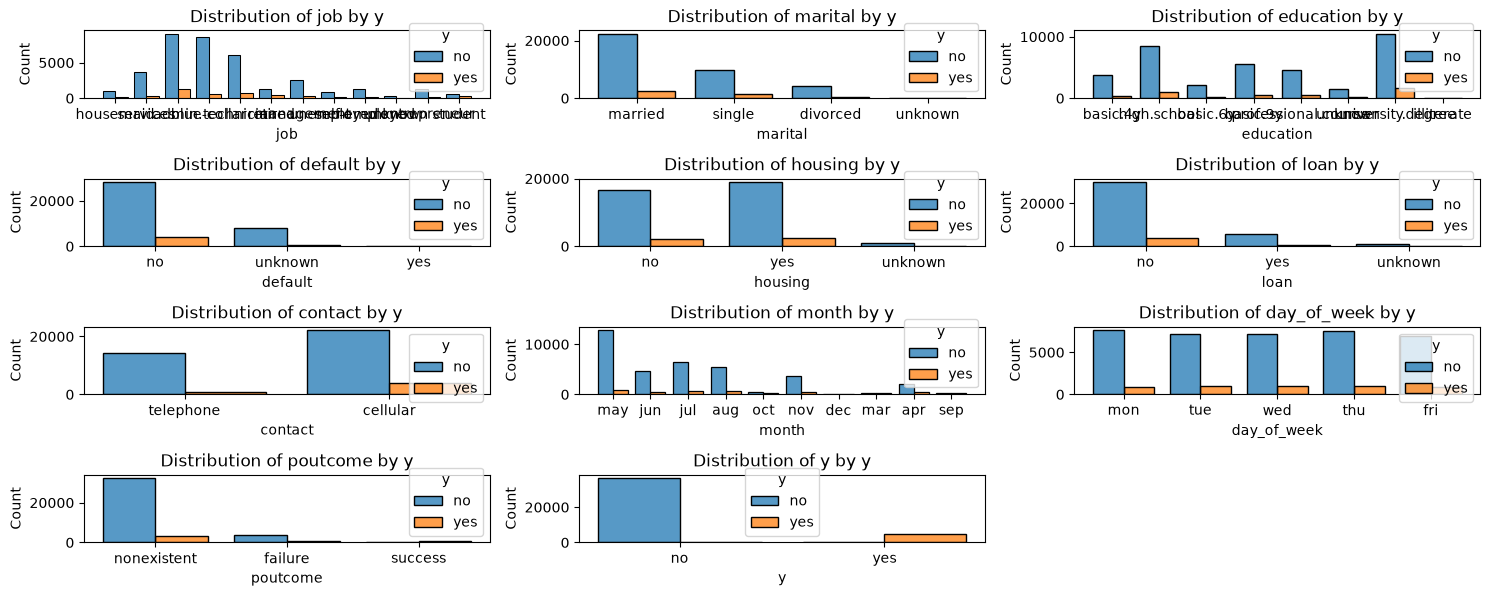

In [91]:
#As knn and svc are taking long time, analyze features corelation for feature selection

#Plot the feature distribution for categorial features to see if the feature is redudant or not
categorical_columns = df.select_dtypes(include=['object']).columns.tolist()
numerical_columns = df.select_dtypes(include=['float64', 'int64']).columns.tolist()

#prepating the layout of plots - in 3 columns
num_features = len(categorical_columns)
num_cols = 3
num_rows = math.ceil(num_features / num_cols)

# Set up the matplotlib figure layout
fig, axes = plt.subplots(num_features, num_cols, figsize=(5 * num_cols, 4 * num_rows))
axes = axes.flatten() # Flatten to loop easily if it's a 2D array

for i, col in enumerate(categorical_columns):
    # Plot histogram; multiple='dodge' creates side-by-side bars for comparison
    sns.histplot(
        data=df, 
        x=col, 
        hue="y", 
        multiple="dodge", 
        shrink=0.8, 
        ax=axes[i]
    )
    axes[i].set_title(f'Distribution of {col} by y')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Count')

# Hide any unused subplots in the grid
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
    
plt.tight_layout()
plt.show()

In [93]:
#all the categorial features look more or less impacting target variable 'y' so not removing any of them right now.

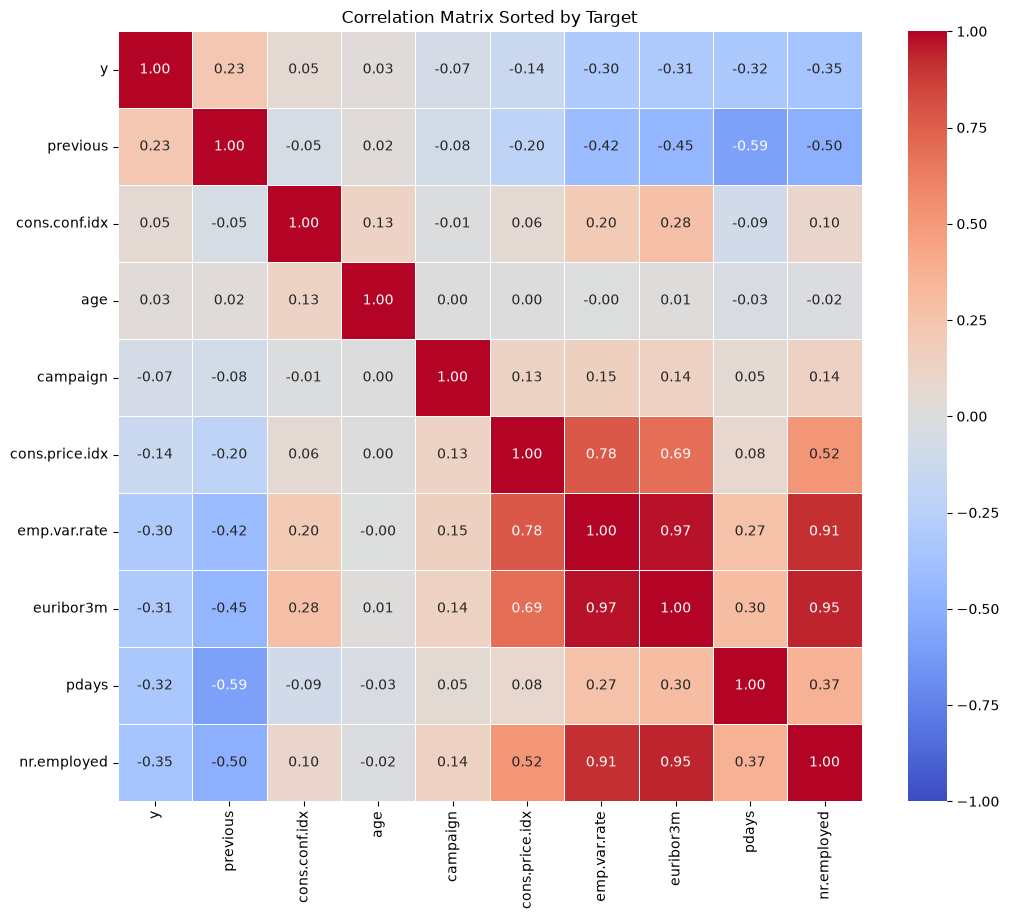

In [95]:
#Check Numerical features now: plot coorelation matrix for numerical features
#compute correlation matrix
df_new = df
df_new['y'] = df['y'].replace({'yes':1, 'no':0})

categorical_columns = df.select_dtypes(include=['object']).columns.tolist()
numerical_columns = df.select_dtypes(include=['float64', 'int64']).columns.tolist()

corr_matrix = df_new[numerical_columns].corr()
target_name = "y"
# Sort the correlation matrix by the correlation strength with the target
sorted_cols = corr_matrix[target_name].sort_values(ascending=False).index
sorted_corr = corr_matrix.loc[sorted_cols, sorted_cols]

#plot Heatmap
plt.figure(figsize=(12,10))
sns.heatmap(
    sorted_corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f",
    linewidths=0.5,
)
plt.title("Correlation Matrix Sorted by Target")
plt.show()

In [97]:
#age, cons.conf.idx and campaign have very small corelation to target variable 'y' but this is linear corelation so not removing them yet.

In [99]:
df = pd.read_csv('data/bank-additional-full.csv', sep = ';')
df.drop(columns=['duration'])

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes


In [101]:
#encode all non-numeric features and build corelation matrix for all features together

#job, marital, education, month, day of week are categorial but have more than 2 values so will convert them to numerical values

encoded_df = df
encoded_df['y'] = encoded_df['y'].replace({'yes':1, 'no':0})
encoded_df['job'] = encoded_df['job'].replace({'blue-collar':1, 'entrepreneur':2, 'housemaid': 3, 'management': 4, 'retired': 5,
                                              'self-employed': 6, 'student': 7, 'technician':8, 'unemployed': 9, 'admin.':10, 'services':11, 'unknown':0})
encoded_df['marital'] = encoded_df['marital'].replace({'married':1, 'single':2, 'divorced':3, 'unknown':0})
encoded_df['education'] = encoded_df['education'].replace({'basic.4y':1, 'basic.6y':2, 'basic.9y':3, 'high.school':4, 
                                                           'professional.course':5, 'university.degree':6, 'illiterate':7, 'unknown':0})
encoded_df['day_of_week'] = encoded_df['day_of_week'].replace({'mon':1, 'tue':2, 'wed':3, 'thu':4, 'fri':5})
encoded_df['month'] = encoded_df['month'].replace({'mar':3, 'apr':4, 'may':5, 'jun':6, 'jul':7, 'aug':8, 'sep':9, 'oct':10, 'nov':11, 'dec':12})

encoded_df_final = pd.get_dummies(encoded_df, drop_first=True)

#print('Dataframe after final encoding: ', encoded_df_final.info())

corr_matrix_all = encoded_df_final.corr()

#Select upper triangle of correlation matrix to avoid looking at duplicates/diagonal
upper_tri = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# Find features with correlation greater than 0.85 or less than 0.85 (either strongly corelated or inverse corelated)
to_drop = [
    column for column in upper_tri.columns if any(upper_tri[column] > 0.85) or any(upper_tri[column] < -0.85)
]
#printing what's being dropped
print('Dropping columns with high corelation: ', to_drop)

df_filtered = encoded_df_final.drop(columns=to_drop)

print(df_filtered.head())

Dropping columns with high corelation:  ['euribor3m', 'nr.employed']
   age  job  marital  education  month  day_of_week  duration  campaign  \
0   56    3        1          1      5            1       261         1   
1   57   11        1          4      5            1       149         1   
2   37   11        1          4      5            1       226         1   
3   40   10        1          2      5            1       151         1   
4   56   11        1          4      5            1       307         1   

   pdays  previous  ...  y  default_unknown  default_yes  housing_unknown  \
0    999         0  ...  0            False        False            False   
1    999         0  ...  0             True        False            False   
2    999         0  ...  0            False        False            False   
3    999         0  ...  0            False        False            False   
4    999         0  ...  0            False        False            False   

   housing_yes  l

In [103]:
#Re-run baseline with filtered dataset
baseline_score = ''
X= df_filtered.drop(columns=['y'])
y=df_filtered['y']

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### BEGIN SOLUTION
dummy_clf = DummyClassifier().fit(X_train, y_train)
baseline_score = dummy_clf.score(X_test, y_test)
print(baseline_score)

0.8865015780529255


In [105]:
models = {
    'logisticregression': (LogisticRegression(random_state=42, max_iter = 1000), {}),
    'knn': (KNeighborsClassifier(), {}),
    'svc': (SVC(), {}),
    'decisiontreeclassifier': (DecisionTreeClassifier(), {})
}
results_df = []

# Train and evaluate each model
for name, (model, params) in models.items():
    # Create a pipeline with StandardScaler and the model
    pipeline = Pipeline([
        #('preprocessor', preprocessor),
        (name, model)
    ])
    
    # Fit the model and time it
    start_time = time.time()
    pipeline.fit(X_train, y_train)
    fit_time = time.time() - start_time
    
    # Evaluate on training and test sets
    train_score = pipeline.score(X_train, y_train)
    test_score = pipeline.score(X_test, y_test)
    
    # Append the results
    results_df.append([name,fit_time, train_score, test_score])

# Create the results DataFrame
results_df = pd.DataFrame(results_df, columns=['Model', 'Train Time', 'Train Accuracy', 'Test Accuracy'])
results_df.set_index('Model', inplace=True)

# Save to JSON (for submission if needed)
results_df.to_json('data/model_results_2.json')

dfResults = pd.read_json(r'data/model_results_2.json')
dfResults

,Train Time,Train Accuracy,Test Accuracy
logisticregression,1.914592,0.907284,0.907016
knn,0.003197,0.925645,0.899733
svc,7.855997,0.902640,0.901554
decisiontreeclassifier,0.097564,1.000000,0.879461


In [107]:
#now try the models along with default parameters with GridSearchCV
# Define the models and hyperparameters
models = {
    'knn': (KNeighborsClassifier(), {'knn__n_neighbors': [3, 7]}),
    'logisticregression': (LogisticRegression(max_iter=1000), {'logisticregression__C': [0.1, 10]}),
    'svc': (SVC(), {'svc__C': [0.1, 1, 10], 'svc__kernel': ['linear']}),
    'decisiontreeclassifier': (DecisionTreeClassifier(), {'decisiontreeclassifier__max_depth': [5, 10, 15]})
}

#Use all 4 models again with default parameters using GridSearchCV 
results = []
dtree_feature_importances = pd.Series(dtype='float64')


# Train and evaluate each model
for name, (model, params) in models.items():
    # Create a pipeline with StandardScaler and the model
    pipeline = Pipeline([
     #   ('preprocessor', preprocessor),
        (name, model)
    ])
    
    # Perform grid search
    grid_search = GridSearchCV(pipeline, param_grid=params, cv=5, n_jobs=-1)
    
    # Fit the model and time it
    start_time = time.time()
    grid_search.fit(X_train, y_train)
    fit_time = (time.time() - start_time) / len(grid_search.cv_results_['mean_fit_time'])
    
    # Get the best estimator
    best_model = grid_search.best_estimator_
    
    # Evaluate on training and test sets
    train_score = best_model.score(X_train, y_train)
    test_score = best_model.score(X_test, y_test)
    
    # Append the results
    results.append([name,fit_time, train_score, test_score])
    if name == "decisiontreeclassifier":
        dtree_feature_importances = pd.Series(best_model.named_steps['decisiontreeclassifier'].feature_importances_, index=X_train.columns)

# Create the results DataFrame
results_df = pd.DataFrame(results, columns=['Model', 'Train Time', 'Train Accuracy', 'Test Accuracy'])
results_df.set_index('Model', inplace=True)

# Save to JSON (for submission if needed)
results_df.to_json('data/model_results_2.json')

dfResults = pd.read_json(r'data/model_results_2.json')
dfResults

,Train Time,Train Accuracy,Test Accuracy
knn,3.184482,0.920759,0.901190
logisticregression,2.394371,0.907436,0.906895
svc,159.389934,0.905038,0.899733
decisiontreeclassifier,0.957584,0.912868,0.911872


In [109]:
#Decision tree with different parameters: min_samples_leaf, min_samples_split
pipeline = Pipeline([
        ('decisiontreeclassifier', DecisionTreeClassifier())
    ])
param_grid={'decisiontreeclassifier__max_depth': [5,10,15],
             'decisiontreeclassifier__min_samples_leaf': [1,2,4],
             'decisiontreeclassifier__min_samples_split': [1,2]}
 # Perform grid search
grid_search = GridSearchCV(pipeline, param_grid=param_grid, cv=5, n_jobs=-1)

# Fit the model and time it
start_time = time.time()
grid_search.fit(X_train, y_train)
fit_time = (time.time() - start_time) / len(grid_search.cv_results_['mean_fit_time'])

# Get the best estimator
best_model = grid_search.best_estimator_

# Evaluate on training and test sets
train_score = grid_search.score(X_train, y_train)
test_score = grid_search.score(X_test, y_test)

# Append the results
results.append(['decisiontree-bestfeatures',fit_time, train_score, test_score])

# Create the results DataFrame
results_df = pd.DataFrame(results, columns=['Model', 'Train Time', 'Train Accuracy', 'Test Accuracy'])
results_df.set_index('Model', inplace=True)

# Save to JSON (for submission if needed)
results_df.to_json('data/model_results_2.json')

dfResults = pd.read_json(r'data/model_results_2.json')
dfResults


,Train Time,Train Accuracy,Test Accuracy
knn,3.184482,0.920759,0.901190
logisticregression,2.394371,0.907436,0.906895
svc,159.389934,0.905038,0.899733
decisiontreeclassifier,0.957584,0.912868,0.911872
decisiontree-bestfeatures,0.279350,0.912868,0.911872


Raw Confusion Matrix:
 [[7015  288]
 [ 438  497]]


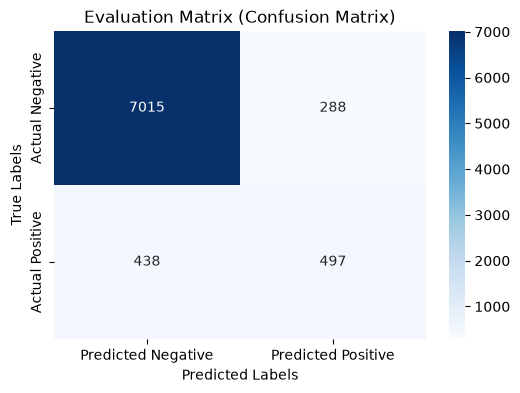

In [111]:
from sklearn.metrics import confusion_matrix, classification_report

# Step 1: Generate predictions using your trained model and test features
# (Replace 'model' with your actual trained model object)
y_pred = best_model.predict(X_test) 

# Step 2: Generate the raw evaluation matrix
matrix = confusion_matrix(y_test, y_pred)
print("Raw Confusion Matrix:\n", matrix)

# Step 3: Optional - Plot it as a readable heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted Negative', 'Predicted Positive'],
            yticklabels=['Actual Negative', 'Actual Positive'])
plt.ylabel('True Labels')
plt.xlabel('Predicted Labels')
plt.title('Evaluation Matrix (Confusion Matrix)')
plt.show()

##### Questions